# Comparación de modelos
Lee `runs/*/metrics/eval_by_resolution.csv` (uno por experimento) y compara.
Fase 1: ViT sin FT · Fase 2: ViT + FT · Fase 3: MSViT sin FT. Los resultados con fine-tuning se presentan **separados** (no son generalización zero-shot).

In [1]:
import glob, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import sys; sys.path.insert(0, '..')
from src.utils.naming import fig_name
RUNS = Path('../runs'); OUT = Path('../figures/comparison'); OUT.mkdir(parents=True, exist_ok=True)
dfs = [pd.read_csv(p) for p in glob.glob(str(RUNS / '*' / 'metrics' / 'eval_by_resolution.csv'))]
df = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()
df.head()

,experiment,phase,model,finetune,R_train,R_test,H,W,accuracy,precision_macro,recall_macro,f1_macro,delta_acc,delta_acc_pct,seed,R_finetune,acc_zero_shot_source
0,f1c_vit_train_r128x128,1,vit,False,R128x128,R128x128,128,128,0.998889,0.998896,0.998889,0.998889,0.000000,0.000000,42,NaN,NaN
1,f1c_vit_train_r128x128,1,vit,False,R128x128,R32x32,32,32,0.345556,0.200436,0.345556,0.223603,0.653333,65.406007,42,NaN,NaN
2,f1c_vit_train_r128x128,1,vit,False,R128x128,R64x64,64,64,0.092222,0.020149,0.092222,0.032797,0.906667,90.767519,42,NaN,NaN
3,f1c_vit_train_r128x128,1,vit,False,R128x128,R96x64,96,64,0.307778,0.173852,0.307778,0.202125,0.691111,69.187987,42,NaN,NaN
4,f1c_vit_train_r32x32,1,vit,False,R32x32,R32x32,32,32,0.996667,0.996732,0.996667,0.996674,0.000000,0.000000,42,NaN,NaN


## Tabla: accuracy por resolución

In [2]:
tab = df.pivot_table(index='R_test', columns='experiment', values='accuracy')
order = list(df.drop_duplicates('R_test').sort_values(['H', 'W'])['R_test'])
tab.loc[order].style.format('{:.3f}')

experiment,f1_vit_base_r64,f1c_vit_train_r128x128,f1c_vit_train_r32x32,f1c_vit_train_r96x64,f2_vit_ft_r128x128,f2_vit_ft_r32x32,f2_vit_ft_r96x64
R_test,,,,,,,
R32x32,0.252,0.346,0.997,0.167,0.234,0.998,0.116
R64x64,1.000,0.092,0.268,0.294,0.813,0.721,0.544
R96x64,0.169,0.308,0.176,0.999,0.170,0.121,0.999
R128x128,0.167,0.999,0.167,0.181,0.998,0.197,0.167


## Degradación ΔA respecto a R_train

In [3]:
df.pivot_table(index='R_test', columns='experiment', values='delta_acc').loc[order].style.format('{:+.3f}')

experiment,f1_vit_base_r64,f1c_vit_train_r128x128,f1c_vit_train_r32x32,f1c_vit_train_r96x64,f2_vit_ft_r128x128,f2_vit_ft_r32x32,f2_vit_ft_r96x64
R_test,,,,,,,
R32x32,+0.748,+0.653,+0.000,+0.832,+0.766,+0.002,+0.884
R64x64,+0.000,+0.907,+0.729,+0.704,+0.187,+0.279,+0.456
R96x64,+0.831,+0.691,+0.821,+0.000,+0.830,+0.879,+0.001
R128x128,+0.833,+0.000,+0.830,+0.818,+0.002,+0.803,+0.833


## Accuracy vs resolución (sin fine-tuning)

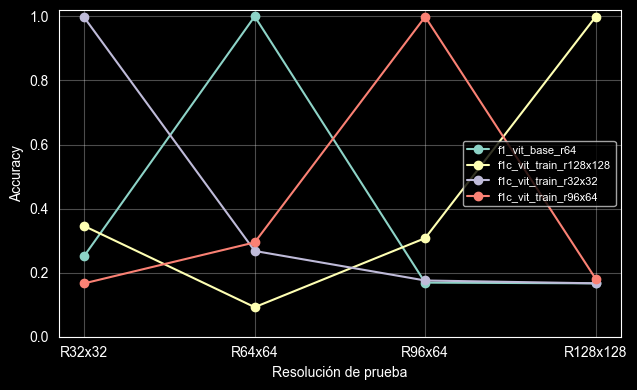

In [4]:
zs = df[~df['finetune']]
fig, ax = plt.subplots(figsize=(6.5, 4))
for exp, g in zs.groupby('experiment'):
    g = g.set_index('R_test').loc[order]
    ax.plot(g.index, g['accuracy'], 'o-', label=exp)
ax.set_ylim(0, 1.02); ax.grid(alpha=.3); ax.set_xlabel('Resolución de prueba'); ax.set_ylabel('Accuracy'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / fig_name('comparison', 'acc_vs_resolution', n_models=zs['experiment'].nunique()), dpi=150); plt.show()

## F1 macro por resolución

In [5]:
df.pivot_table(index='R_test', columns='experiment', values='f1_macro').loc[order].style.format('{:.3f}')

experiment,f1_vit_base_r64,f1c_vit_train_r128x128,f1c_vit_train_r32x32,f1c_vit_train_r96x64,f2_vit_ft_r128x128,f2_vit_ft_r32x32,f2_vit_ft_r96x64
R_test,,,,,,,
R32x32,0.188,0.224,0.997,0.048,0.127,0.998,0.047
R64x64,1.000,0.033,0.192,0.212,0.756,0.671,0.469
R96x64,0.054,0.202,0.093,0.999,0.058,0.071,0.999
R128x128,0.048,0.999,0.048,0.076,0.998,0.116,0.048


In [6]:
ft  = df[df['finetune'] & (df['R_test'] == df['R_finetune'])].set_index('R_test')['accuracy'].rename('ViT + FT')
sin = df[(~df['finetune']) & (df['experiment'] == 'f1_vit_base_r64')].set_index('R_test')['accuracy'].rename('ViT sin FT')
pd.concat([sin, ft], axis=1).loc[order].style.format('{:.3f}')

,ViT sin FT,ViT + FT
R_test,,
R32x32,0.252,0.998
R64x64,1.000,nan
R96x64,0.169,0.999
R128x128,0.167,0.998
